In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [20]:
summary_path = Path("../../../data/processed/final_summary_dataset/overview_dataset_results_all.csv")

In [21]:
summary = pd.read_csv(summary_path)

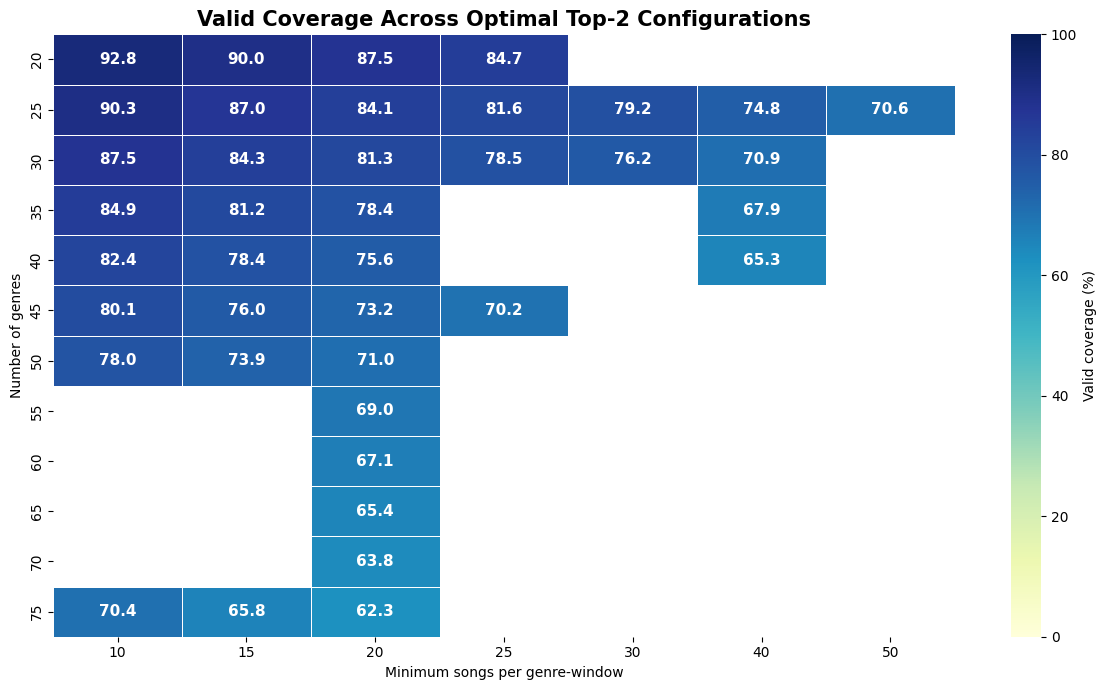

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

OUTPUT_DIR = Path("plots")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

top_value = 2

plot_data = summary[
    (summary["top_candidates_per_song"] == top_value) &
    (summary["solver.solver_status"] == "OPTIMAL")
].copy()

plot_data = (
    plot_data.groupby(
        ["total_genres", "min_tracks"],
        as_index=False
    )["valid_coverage_pct"]
    .mean()
)

heatmap_data = plot_data.pivot(
    index="total_genres",
    columns="min_tracks",
    values="valid_coverage_pct"
)

heatmap_data = heatmap_data.sort_index().sort_index(axis=1)

fig, ax = plt.subplots(figsize=(12, 7))

sns.heatmap(
    heatmap_data,
    ax=ax,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    vmin=0,
    vmax=100,
    mask=heatmap_data.isna(),
    linewidths=0.7,
    linecolor="white",
    cbar_kws={"label": "Valid coverage (%)"},
    annot_kws={"size": 11, "weight": "bold"}
)

ax.set_title(
    "Valid Coverage Across Optimal Top-2 Configurations",
    fontsize=15,
    weight="bold"
)
ax.set_xlabel("Minimum songs per genre-window")
ax.set_ylabel("Number of genres")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "optimal_top2_coverage_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()